In [1]:
#1 Imports
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_curve
)

In [2]:
from google.colab import files

uploaded = files.upload()

Saving X_test_medianonly.csv to X_test_medianonly.csv
Saving X_train_medianonly.csv to X_train_medianonly.csv
Saving y_test_medianonly.csv to y_test_medianonly.csv
Saving y_train_medianonly.csv to y_train_medianonly.csv


In [3]:
#2 Loading the leakage-free, pre-split, pre-imputed data
X_train = pd.read_csv("X_train_medianonly.csv")
X_test = pd.read_csv("X_test_medianonly.csv")
y_train = pd.read_csv("y_train_medianonly.csv").squeeze()
y_test = pd.read_csv("y_test_medianonly.csv").squeeze()

print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)
print("\nTrain class distribution:")
print(y_train.value_counts(normalize=True))

Train shape: (614, 8)
Test shape : (154, 8)

Train class distribution:
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64


In [4]:
#3 Building the Scaler + SMOTE + Logistic Regression pipeline
lr_pipeline = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("clf", LogisticRegression(random_state=42, max_iter=2000))
])

In [5]:
#4 Defining the hyperparameter search space
param_grid = [
    {
        "clf__solver": ["liblinear"],
        "clf__penalty": ["l1", "l2"],
        "clf__C": [0.001, 0.01, 0.1, 1, 10, 100]
    },
    {
        "clf__solver": ["saga"],
        "clf__penalty": ["elasticnet"],
        "clf__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9],
        "clf__C": [0.001, 0.01, 0.1, 1, 10, 100]
    }
]

In [6]:
#5 Cross-validation strategy
cv_strategy = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

In [7]:
#6 Running GridSearchCV
grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV ROC-AUC:", grid_search.best_score_)

Fitting 10 folds for each of 42 candidates, totalling 420 fits
Best Parameters: {'clf__C': 0.1, 'clf__l1_ratio': 0.5, 'clf__penalty': 'elasticnet', 'clf__solver': 'saga'}
Best CV ROC-AUC: 0.8445346320346321


In [8]:
#7 Evaluating the tuned model on the test set
best_lr_model = grid_search.best_estimator_

y_pred = best_lr_model.predict(X_test)
y_prob = best_lr_model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("="*50)
print("TUNED LOGISTIC REGRESSION RESULTS")
print("="*50)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC AUC  : {roc_auc:.4f}")

print("\nClassification Report")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

TUNED LOGISTIC REGRESSION RESULTS
Accuracy : 0.7078
Precision: 0.5714
Recall   : 0.6667
F1 Score : 0.6154
ROC AUC  : 0.8050

Classification Report
              precision    recall  f1-score   support

           0       0.80      0.73      0.76       100
           1       0.57      0.67      0.62        54

    accuracy                           0.71       154
   macro avg       0.69      0.70      0.69       154
weighted avg       0.72      0.71      0.71       154


Confusion Matrix
[[73 27]
 [18 36]]


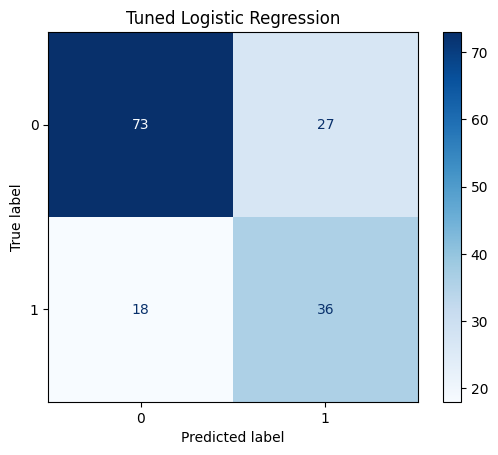

In [9]:
#8 Plotting Confusion Matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Tuned Logistic Regression")
plt.show()

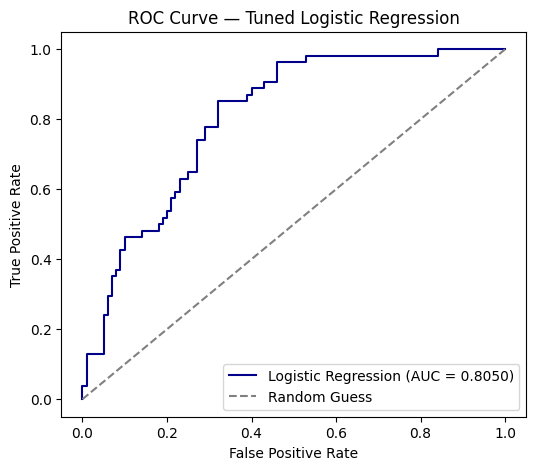

In [10]:
#9 Plotting ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="darkblue", label=f"Logistic Regression (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Tuned Logistic Regression")
plt.legend(loc="lower right")
# Save the figure
plt.savefig("roc_curve_logistic_regression.png", dpi=300, bbox_inches="tight")


plt.show()

In [11]:
#10 Extracting model coefficients for interpretation
coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": best_lr_model.named_steps["clf"].coef_[0]
}).sort_values(by="Coefficient", key=abs, ascending=False)

print(coef_df)

                    Feature  Coefficient
1                   Glucose     1.097734
5                       BMI     0.662726
0               Pregnancies     0.235258
6  DiabetesPedigreeFunction     0.202861
7                       Age     0.138174
3             SkinThickness     0.035856
2             BloodPressure     0.000000
4                   Insulin     0.000000


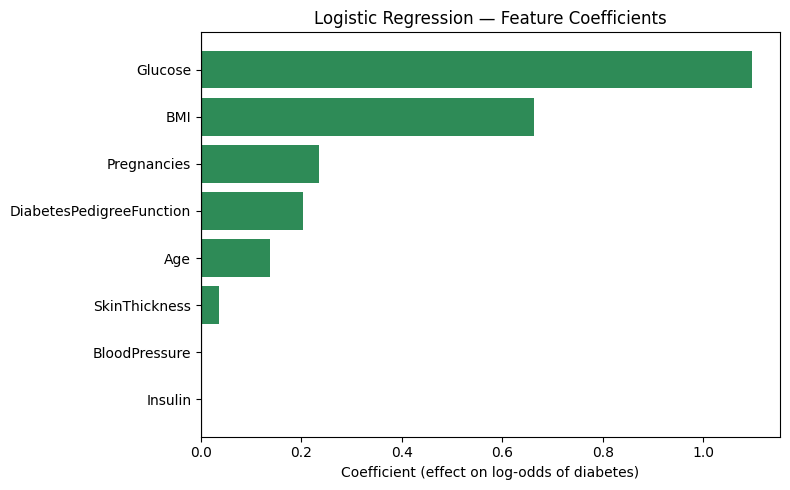

In [12]:
#11 Plotting coefficients
plt.figure(figsize=(8, 5))
colors = ["seagreen" if c > 0 else "indianred" for c in coef_df["Coefficient"]]
plt.barh(coef_df["Feature"], coef_df["Coefficient"], color=colors)
plt.gca().invert_yaxis()
plt.xlabel("Coefficient (effect on log-odds of diabetes)")
plt.title("Logistic Regression — Feature Coefficients")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()